In [170]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import visualastro as va
from matplotlib.patches import Wedge, Circle

In [2]:
sys.platform

'linux'

In [3]:
plt.style.use(['science','notebook'])
plt.rcParams["font.family"] = "serif"

In [4]:
from amuse.units import units, constants, generic_unit_system, nbody_system
from amuse.datamodel import Particle, Particles

# related to project
from amuse.ext.solarsystem import new_solar_system
from amuse.ext.orbital_elements import rel_posvel_arrays_from_orbital_elements
from amuse.community.huayno.interface import Huayno

# random lol
from amuse.ic.plummer import new_plummer_model
from amuse.ic.fractalcluster import new_fractal_cluster_model

In [5]:
def plot_fractal(bodies, units, title=None, limits=1, **kwargs):
    fig = plt.figure(figsize=(5, 5))
    ax = fig.add_subplot(1, 1, 1)
    ax.scatter(bodies.x.value_in(units), bodies.y.value_in(units), **kwargs)
    ax.set_xlim((-limits, limits))
    ax.set_ylim((-limits, limits))
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_title(title)

In [6]:
converter = nbody_system.nbody_to_si(1 | units.MSun, 1 | units.au)
particles = new_fractal_cluster_model(N=2000, fractal_dimension=1.6, convert_nbody=converter)

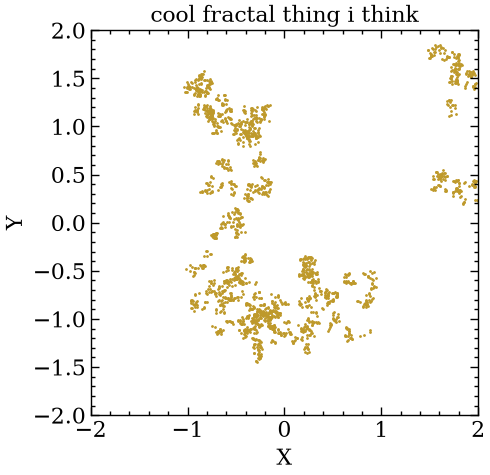

In [7]:
plot_fractal(particles, units.au, limits=2, s=1, c='soup of the day', title="cool fractal thing i think")

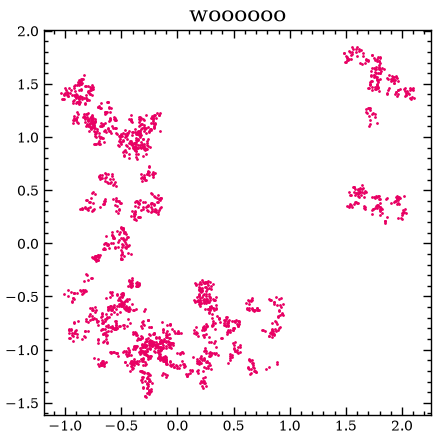

In [8]:
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(1, 1, 1)
va.scatter(particles.x.value_in(units.au), particles.y.value_in(units.au), s=1, title='woooooo', color='борщ')

In [18]:
#functions!
def orbital_radii(particles):
    moon = particles[0]
    debris = particles[1:]

    r = (
        (debris.x - moon.x)**2 +
        (debris.y - moon.y)**2 +
        (debris.z - moon.z)**2
    ).sqrt()

    return r.value_in(units.km)


def compare_radii(initial, final):
    r0 = orbital_radii(initial)
    r1 = orbital_radii(final)
    dr = r1 - r0

    print(f"Initial mean radius: {r0.mean():.3f} km")
    print(f"Final mean radius:   {r1.mean():.3f} km")
    print(f"Change in mean:      {dr.mean():.3f} km")
    print(f"Mean absolute change:{np.abs(dr).mean():.3f} km")
    print(f"Maximum change:      {np.abs(dr).max():.3f} km")


def evolve_to(time_days, particles):
    gravity = Huayno(converter, channel_type="sockets")
    try:
        gravity.particles.add_particles(particles)
        gravity.evolve_model(time_days | units.day)
        result = gravity.particles.copy()
    finally:
        gravity.stop()

    return result

In [11]:
#Set up
obj = new_solar_system()
new_system = obj[
    (obj.name == "SUN") |
    (obj.name == "JUPITER") |
    (obj.name == "SATURN")
].copy()
saturn = new_system[new_system.name == "SATURN"][0]

#iapetus properties from solar_system_moons.py
iapetus = Particle()
iapetus.name = "IAPETUS"
iapetus.mass = 1.81e21 | units.kg
iapetus.radius = 746 | units.km

#orbital parameters
a = 3560854 | units.km
e = 0.0293
M = np.deg2rad(201.789)  #mean anomaly

|S8


In [12]:
#not exactly sure why i have to do this but it's in the textbook
E = M
for _ in range(6):
    E -= (E - e*np.sin(E) - M) / (1 - e*np.cos(E))

f = 2*np.arctan2(
    np.sqrt(1+e)*np.sin(E/2),
    np.sqrt(1-e)*np.cos(E/2)
)

In [123]:
iapetus_kg = iapetus.mass.value_in(units.kg)
print(np.format_float_scientific(iapetus_kg))

1.81e+21


median debris mass: 9.062e+14 [kg]
total mass in disk: 1.810e+19 [kg]


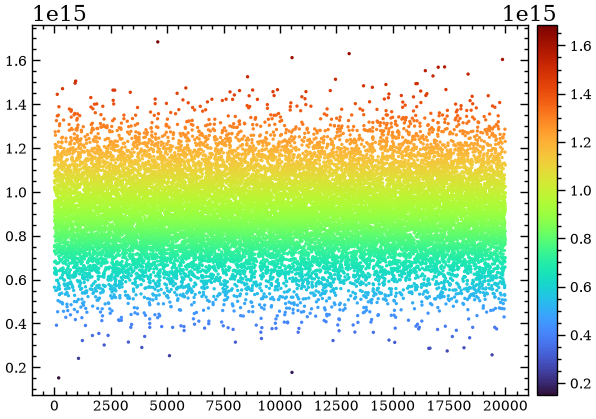

In [131]:
total_mass = 0.01*iapetus_kg
N = 20000

def debris_disk_masses(N, total_mass, chunk_median, chunk_std):
    
    mass_fractions = np.random.normal(chunk_median, chunk_std, N)
    mass_fractions[mass_fractions < 1e-5] = 1e-5 # get rid of negative chunks/negative masses lol
    mass_chunk = np.sum(mass_fractions)

    masses = mass_fractions * total_mass/mass_chunk
    print("median debris mass: {} [kg]".format(np.format_float_scientific(np.median(masses),3)))
    return masses

masses = debris_disk_masses(N, total_mass, 1000, 200)
print("total mass in disk: {} [kg]".format(np.format_float_scientific(np.sum(masses),3)))
va.scatter(masses, s = 2, c = masses)

median debris mass: 9.011e+15 [kg]


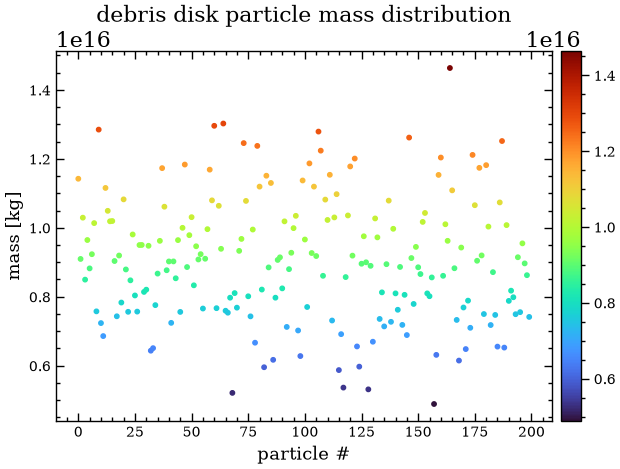

In [241]:
#calc orbital position and velocity
pos, vel = rel_posvel_arrays_from_orbital_elements(
    saturn.mass,
    iapetus.mass,
    a,
    eccentricity=e,
    true_anomaly=f | units.rad,
    inclination=8.298 | units.deg,
    argument_of_periapsis=271.606 | units.deg,
    longitude_of_the_ascending_node=81.105 | units.deg
)

#place iapetus around saturn
iapetus.position = saturn.position + pos[0]
iapetus.velocity = saturn.velocity + vel[0]
new_system.add_particle(iapetus)

N = 200
debris = Particles(N)
np.random.seed(42)

#random positions in a disk around iapetus
disk_inner_r_km = 1.3 * iapetus.radius.value_in(units.km)
disk_outer_r_km = 2.5 * iapetus.radius.value_in(units.km)

r = np.random.uniform(disk_inner_r_km, disk_outer_r_km, N) | units.km
phi = np.random.uniform(0, 2*np.pi, N)
v = (constants.G * iapetus.mass / r).sqrt()

#particle properties
# distribute some total amount of mass over some number of particles
total_disk_mass = 0.001*iapetus_kg
m = debris_disk_masses(N, total_disk_mass, 10, 2)
va.scatter(m, s = 10, c = m, title = "debris disk particle mass distribution", xlabel = "particle #", ylabel = "mass [kg]")
debris.mass = m | units.kg
debris.radius = 0 | units.km

#positions
debris.x = iapetus.x + r * np.cos(phi)
debris.y = iapetus.y + r * np.sin(phi)
debris.z = iapetus.z

#velocities
debris.vx = iapetus.vx - v * np.sin(phi)
debris.vy = iapetus.vy + v * np.cos(phi)
debris.vz = iapetus.vz

#finally making debris
new_system.add_particles(debris)

disk_system = Particles()
disk_system.add_particle(iapetus)
disk_system.add_particles(debris)
disk_system.move_to_center()

#making saturn
saturn_system = Particles()
saturn_system.add_particle(iapetus)
saturn_system.add_particles(debris)
saturn_system.add_particle(saturn)
saturn_system.move_to_center()

converter = nbody_system.nbody_to_si(iapetus.mass, iapetus.radius)

In [65]:
saturn_system

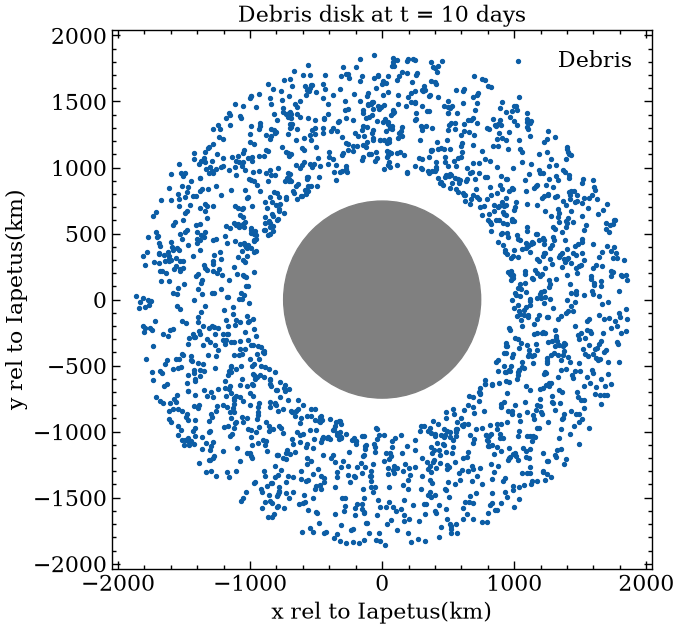

Without Saturn:
Initial mean radius: 1416.180 km
Final mean radius:   1416.227 km
Change in mean:      0.047 km
Mean absolute change:0.047 km
Maximum change:      0.157 km

With Saturn:
Initial mean radius: 1416.180 km
Final mean radius:   1416.230 km
Change in mean:      0.050 km
Mean absolute change:0.402 km
Maximum change:      5.436 km
Mean absolute difference: 0.392766031938 km
Maximum difference: 5.42726339058 km


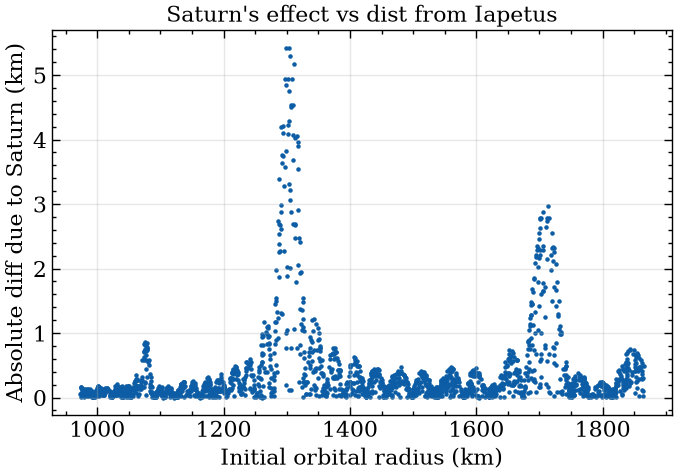

In [14]:
after_no_saturn = evolve_to(5, disk_system)
after_saturn = evolve_to(5, saturn_system)

#plot debris disk with Saturn's gravity
plot_disk(after_saturn[:-1], time=10)

#compare orbital radii
print("Without Saturn:")
compare_radii(disk_system, after_no_saturn)

print("\nWith Saturn:")
compare_radii(saturn_system[:-1], after_saturn[:-1])

r_no = orbital_radii(after_no_saturn)
r_sat = orbital_radii(after_saturn[:-1])
difference = r_sat - r_no

print("Mean absolute difference:", np.abs(difference).mean(), "km")
print("Maximum difference:", np.abs(difference).max(), "km")

plt.figure(figsize=(8, 5))
plt.scatter(orbital_radii(disk_system), np.abs(difference), s=5)
plt.xlabel("Initial orbital radius (km)")
plt.ylabel("Absolute diff due to Saturn (km)")
plt.title("Saturn's effect vs dist from Iapetus")
plt.grid(alpha=0.3)
plt.show()

In [242]:
t = 300
after_no_saturn = evolve_to(t, disk_system)
after_saturn = evolve_to(t, saturn_system)

In [225]:
def plot_disk(particles, time=None, masses=None, scale=1, limits = 3000):
    moon = particles[0]
    debris = particles[1:]

    x = (debris.x - moon.x).value_in(units.km)
    y = (debris.y - moon.y).value_in(units.km)
    R = moon.radius.value_in(units.km)

    fig, ax = plt.subplots(figsize=(7, 7))

    if masses is not None:
        m = masses*scale
        m[m<3] = 3
        print(m)
        va.scatter(x, y, s=m, c=masses, limits = limits)
    else:
        m = 8
        va.scatter(x, y, s=m, color = "Holy Blue", limits = limits)
    
    ax.add_patch(Circle((0, 0), R, color="borscht", alpha = 0.5, label = "Iapetus"))
    ax.add_patch(Wedge((0, 0), disk_outer_r_km, 0, 360, width = disk_outer_r_km - disk_inner_r_km, 
                       color="nebula", alpha = 0.5, label = "Initial Debris Disk"))

    ax.set_xlabel("x [km]")
    ax.set_ylabel("y [km]")
    ax.set_title(f"Debris disk at t = {time} days" if time is not None else "Debris disk")
    ax.legend(fontsize = 10)

    # ax.set_aspect("equal")
    # ax.set_xlim(-3000,3000)
    # ax.set_ylim(-3000,3000)
    
    plt.show()

[ 57.11228606  45.47807018  51.46466008  42.4775651   48.22398442
  44.1090473   46.1663738   50.67850013  37.87673924  64.2397609
  36.17575838  34.29023386  55.77749137  52.45836306  50.94083251
  50.97910699  45.17690056  37.16088645  45.97443125  39.15439009
  54.12003717  43.95584467  37.81083174  42.37685326  49.02798012
  40.18185456  37.84051158  47.49503934  47.50662722  40.69615559
  41.0213663   47.38963397  32.17170802  32.53963146  38.78047106
  43.35451499  48.10389209  58.65096179  53.05613455  43.83917283
  45.11558596  36.20735132  45.12014257  42.67328204  48.21087094
  37.79512822  49.99184148  59.1707093   44.30272436  48.92635666
  51.53885078  41.65374588  47.3175588   45.401883    46.17253415
  38.28623991  45.50982901  49.79847855  58.4316545   53.97648466
  64.79041723  38.33752585  53.18892764  46.9484587   65.12210958
  37.96661201  37.68199109  39.85878848  26.05050229  40.52576607
  38.41193285  46.65002805  48.38330358  62.2813664   53.89635249
  40.062483

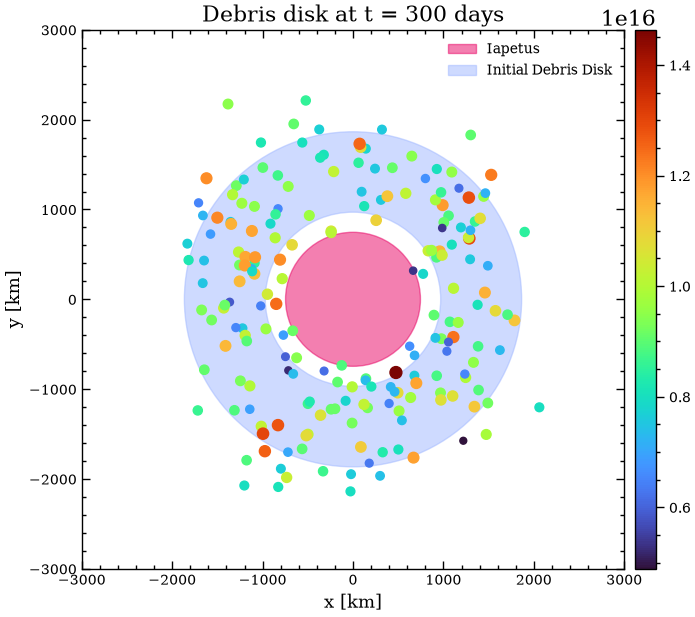

In [243]:
#plot debris disk with Saturn's gravity
plot_disk(after_saturn[:-1], masses = m, scale = 0.5e-14, time=t, limits = 3000)

[ 366.89471513  339.0511894   367.23468342  217.26652616  344.77312622
  386.3727354   467.20721439  323.23722378  302.30535022  324.42820873
  426.63843007  384.32721266  322.4085279   397.63514219  367.61814672
  430.47848274  309.98219294  336.98451041  332.33645057  255.06303722
  381.97376873  379.44476422  360.98539118  343.69738922  258.53535712
  330.2782552   335.89888354  302.75369283  348.98413099  389.75808029
  496.65457793  373.20772289  379.19198054  355.24730524  222.22844453
  358.70432304  364.96059433  538.27378676  346.74288062  382.36518669
  358.1130637   276.32765357  443.04076538  414.84849721  417.66844066
  295.02855082  461.79077238  259.51044125  402.94267272  518.59952014]


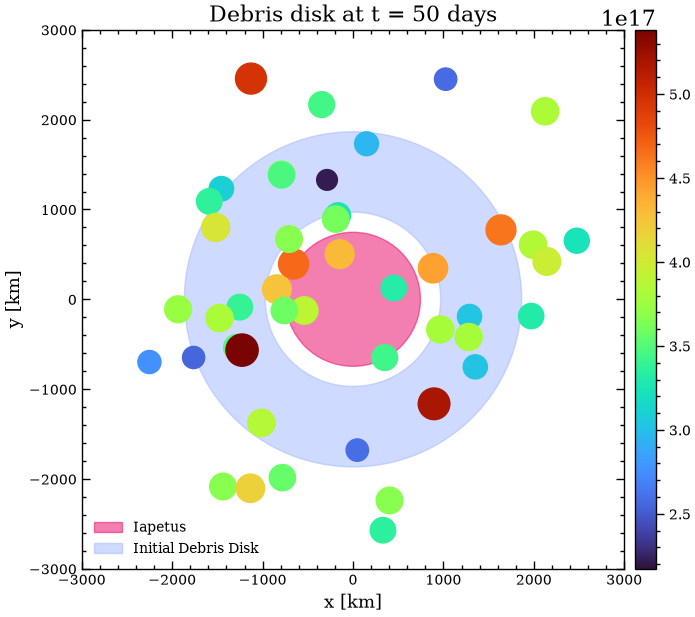

In [228]:
#plot debris disk with Saturn's gravity
plot_disk(after_saturn[:-1], masses = m, scale = 1e-15, time=t, limits = 3000)